# Fair Compensation Project

## Split into train and test sets

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import joblib
import os

df = pd.read_csv('data/cleaned/modelling_features.csv')
print(f"Starting shape: {df.shape}")

Starting shape: (36452, 112)


In [2]:
# drop features that are not useful for regression
non_features = [
    'job_id',
    'fairness_index',
    'fairness_label',
    'annual_mean',
    'annual_low',
    'annual_high','job_title', 'company_clean', 'company', 'city', 'state_x',
    'bls_occ_code', 'company_co', 'sector', 'revenue_band',
    'employee_band', 'state_y', 'state_abbr', 'state_name'
]

X = df.drop(columns=non_features)
y = df['fairness_index']


In [25]:
cols_to_scale = [
    'skills_count',
    'revenue_rank',
    'employee_rank',
    'company_score',
    'reviews_count',
    'total_employed',
    'bls_annual_mean',
    'bls_annual_median',
    'bls_p10',
    'bls_p90',
    'pce_2023_in_millions'
]

# split into test and train 
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
)

print(f"X_train: {X_train.shape}")
print(f"X_test:  {X_test.shape}")
print()
print("Train fairness index distribution:")
print(y_train.describe())

X_train: (29161, 93)
X_test:  (7291, 93)

Train fairness index distribution:
count    29161.000000
mean         0.816274
std          0.315813
min          0.107621
25%          0.599843
50%          0.765478
75%          0.974721
max          4.115650
Name: fairness_index, dtype: float64


In [28]:
# fit medians on training data only
train_medians = X_train.median()
print("Train medians used for imputation:")
print(train_medians)

# apply to both
X_train = X_train.fillna(train_medians)
X_test  = X_test.fillna(train_medians)

# check
print("\nNull counts after imputation:")
print(X_train.isnull().sum()[X_train.isnull().sum() > 0])
print("All nulls resolved:", X_train.isnull().sum().sum() == 0)

Train medians used for imputation:
skills_count             -0.311410
revenue_rank              0.213973
employee_rank             0.032777
company_score             0.069848
reviews_count            -0.172987
                            ...   
skill_machine_learning    0.000000
skill_hadoop              0.000000
skill_html                0.000000
skill_phd                 0.000000
skill_cma                 0.000000
Length: 93, dtype: float64

Null counts after imputation:
Series([], dtype: int64)
All nulls resolved: True


## Standardize Numerical Values

In [29]:
scaler = StandardScaler()

# fit ONLY on training data
scaler.fit(X_train[cols_to_scale])

# transform both train and test
X_train[cols_to_scale] = scaler.transform(X_train[cols_to_scale])
X_test[cols_to_scale]  = scaler.transform(X_test[cols_to_scale])

print("Scaled column stats on train (should be ~mean=0, std=1):")
print(X_train[cols_to_scale].describe().round(3))

Scaled column stats on train (should be ~mean=0, std=1):
       skills_count  revenue_rank  employee_rank  company_score  \
count     29161.000     29161.000      29161.000      29161.000   
mean          0.000         0.000         -0.000         -0.000   
std           1.000         1.000          1.000          1.000   
min          -1.462        -3.174         -3.300         -4.876   
25%          -0.695         0.214          0.033         -0.297   
50%          -0.311         0.214          0.033          0.070   
75%           0.456         0.214          1.144          0.436   
max           6.976         1.343          1.144          2.451   

       reviews_count  total_employed  bls_annual_mean  bls_annual_median  \
count      29161.000       29161.000        29161.000          29161.000   
mean           0.000           0.000           -0.000              0.000   
std            1.000           1.000            1.000              1.000   
min           -0.183          -0.91

In [30]:
print("Null counts in feature matrix:")
print(X_train.isnull().sum()[X_train.isnull().sum() > 0])
print()
print("Total rows with any null:", X_train.isnull().any(axis=1).sum())
print("Total rows fully complete:", X_train.notna().all(axis=1).sum())
print()
print("As percentage of training set:")
print((X_train.isnull().sum()[X_train.isnull().sum() > 0] / len(X_train) * 100).round(1))

Null counts in feature matrix:
Series([], dtype: int64)

Total rows with any null: 0
Total rows fully complete: 29161

As percentage of training set:
Series([], dtype: float64)


## Regression Analysis

Now, having split and scaled the data, we will perform various types of regression on the data and see our results.

In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score, KFold

#cross validation setup
cv = KFold(n_splits=5, shuffle=True, random_state=42)

results = []

#helper function
def evaluate_model(name, model):
    cv_scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="r2"
    )

    model.fit(X_train, y_train)
    preds = model.predict(X_test)

    rmse = np.sqrt(mean_squared_error(y_test, preds))
    r2 = r2_score(y_test, preds)

    results.append({
        "Model": name,
        "RMSE": rmse,
        "R2": r2,
        "CV Mean R2": cv_scores.mean(),
        "CV Std": cv_scores.std()
    })

    print(name)
    print("RMSE:", rmse)
    print("R²:", r2)
    print("CV Mean R²:", cv_scores.mean())
    print("CV Std:", cv_scores.std())
    print()

    return preds, cv_scores, model, rmse, r2

## Linear Regression

In [32]:
linear_model = LinearRegression()

print("\n==============================")
print("LINEAR REGRESSION")
print("==============================")

linear_preds, linear_cv, linear_model, linear_rmse, linear_r2 = evaluate_model(
    "Linear Regression",
    linear_model
)


LINEAR REGRESSION
Linear Regression
RMSE: 0.24553716683801238
R²: 0.38973778190495634
CV Mean R²: 0.366753166399727
CV Std: 0.005506687442234986



Linear Regression was used as the baseline regression model for predicting the fairness index. The model achieved moderate predictive performance, demonstrating that the engineered features contained meaningful information related to salary fairness. Since Linear Regression does not use regularization, it served as a useful reference point for evaluating whether additional regularization methods could improve generalization and numerical stability.

## Ridge Regression

In [33]:
ridge_alphas = [1e-6, 1e-4, 1e-2, 1, 10, 100, 1000, 10000]

ridge_rmse = []
ridge_r2 = []

best_ridge_model = None
best_ridge_rmse = float("inf")
best_ridge_preds = None

print("\n==============================")
print("RIDGE REGRESSION")
print("==============================")

for alpha in ridge_alphas:
    model = Ridge(alpha=alpha)

    preds, cv_scores, fitted_model, rmse, r2 = evaluate_model(
        f"Ridge alpha={alpha}",
        model
    )

    ridge_rmse.append(rmse)
    ridge_r2.append(r2)

    if rmse < best_ridge_rmse:
        best_ridge_rmse = rmse
        best_ridge_model = fitted_model
        best_ridge_preds = preds


RIDGE REGRESSION
Ridge alpha=1e-06
RMSE: 0.245537166836696
R²: 0.3897377819114999
CV Mean R²: 0.36675316641865435
CV Std: 0.005506687450704073

Ridge alpha=0.0001
RMSE: 0.24553716670637737
R²: 0.38973778255929215
CV Mean R²: 0.3667531682924358
CV Std: 0.0055066882891211715

Ridge alpha=0.01
RMSE: 0.2455371536997525
R²: 0.3897378472130604
CV Mean R²: 0.3667533554347443
CV Std: 0.005506771990836709

Ridge alpha=1
RMSE: 0.2455360804258089
R²: 0.3897431822674581
CV Mean R²: 0.3667699210130516
CV Std: 0.005513877527794355

Ridge alpha=10
RMSE: 0.2455365351106285
R²: 0.3897409221127184
CV Mean R²: 0.36681518412860353
CV Std: 0.0055229259186725995

Ridge alpha=100
RMSE: 0.24575556924584238
R²: 0.38865165701179427
CV Mean R²: 0.36517395801826225
CV Std: 0.005263716740021822

Ridge alpha=1000
RMSE: 0.24986124347767424
R²: 0.3680542514716433
CV Mean R²: 0.33957336044265707
CV Std: 0.00473465703839841

Ridge alpha=10000
RMSE: 0.2685936187467031
R²: 0.269746943475494
CV Mean R²: 0.237604884224218

Ridge Regression was implemented to reduce overfitting and improve numerical stability by shrinking large coefficients through L2 regularization. Multiple alpha values were tested to analyze the effect of regularization strength on model performance. The results showed that moderate regularization slightly improved RMSE and R² compared to the baseline Linear Regression model, while excessively large alpha values led to underfitting.

## Lasso Regression

In [34]:
lasso_alphas = [1e-6, 1e-5, 1e-4, 1e-3, 1e-2]

lasso_rmse = []
lasso_r2 = []

best_lasso_model = None
best_lasso_rmse = float("inf")
best_lasso_preds = None

print("\n==============================")
print("LASSO REGRESSION")
print("==============================")

for alpha in lasso_alphas:
    model = Lasso(alpha=alpha, max_iter=10000)

    preds, cv_scores, fitted_model, rmse, r2 = evaluate_model(
        f"Lasso alpha={alpha}",
        model
    )

    lasso_rmse.append(rmse)
    lasso_r2.append(r2)

    if rmse < best_lasso_rmse:
        best_lasso_rmse = rmse
        best_lasso_model = fitted_model
        best_lasso_preds = preds


LASSO REGRESSION
Lasso alpha=1e-06
RMSE: 0.24553648199157183
R²: 0.38974118615801023
CV Mean R²: 0.36675704305627016
CV Std: 0.005507995117415635

Lasso alpha=1e-05
RMSE: 0.2455320653756998
R²: 0.3897631401625685
CV Mean R²: 0.3667832132554862
CV Std: 0.005519312714846244

Lasso alpha=0.0001
RMSE: 0.2455995571922679
R²: 0.38942761042437235
CV Mean R²: 0.36670743251588533
CV Std: 0.005544269894466587

Lasso alpha=0.001
RMSE: 0.2478165375494695
R²: 0.37835481797940784
CV Mean R²: 0.3553602299401076
CV Std: 0.005810023284487975

Lasso alpha=0.01
RMSE: 0.27183897969311577
R²: 0.25199333877993724
CV Mean R²: 0.23411704023873298
CV Std: 0.004690410671152955



Lasso Regression was implemented using L1 regularization, which encourages sparsity by forcing less important feature coefficients toward zero. Several alpha values were tested to evaluate how aggressive feature selection affected predictive performance. The results showed that small alpha values performed similarly to Ridge Regression, while larger alpha values significantly reduced performance by removing too many informative features.

## ElasticNet Regression

In [35]:
elastic_alphas = [
    1e-05,
    5e-05,
    1e-04
]

l1_ratios = [
    0.2,
    0.3,
    0.5
]

elastic_results = []

best_elastic_model = None
best_elastic_rmse = float("inf")
best_elastic_preds = None

print("\n==============================")
print("ELASTIC NET")
print("==============================")

for alpha in elastic_alphas:
    for l1 in l1_ratios:
        model = ElasticNet(
            alpha=alpha,
            l1_ratio=l1,
            max_iter=10000
        )

        preds, cv_scores, fitted_model, rmse, r2 = evaluate_model(
            f"ElasticNet alpha={alpha} l1={l1}",
            model
        )

        elastic_results.append({
            "alpha": alpha,
            "l1_ratio": l1,
            "rmse": rmse,
            "r2": r2
        })

        if rmse < best_elastic_rmse:
            best_elastic_rmse = rmse
            best_elastic_model = fitted_model
            best_elastic_preds = preds


ELASTIC NET
ElasticNet alpha=1e-05 l1=0.2
RMSE: 0.245535443347853
R²: 0.3897463490579436
CV Mean R²: 0.3667640920218191
CV Std: 0.005510641853971406

ElasticNet alpha=1e-05 l1=0.3
RMSE: 0.24553490952457654
R²: 0.3897490025831931
CV Mean R²: 0.36676715883539784
CV Std: 0.0055118687211225155

ElasticNet alpha=1e-05 l1=0.5
RMSE: 0.24553393768185372
R²: 0.38975383339782865
CV Mean R²: 0.36677273511458747
CV Std: 0.005514454858685131

ElasticNet alpha=5e-05 l1=0.2
RMSE: 0.2455313138644218
R²: 0.38976687571686264
CV Mean R²: 0.3667959689359551
CV Std: 0.005523344649841714

ElasticNet alpha=5e-05 l1=0.3
RMSE: 0.24553066776600688
R²: 0.3897700872838876
CV Mean R²: 0.3668052493540511
CV Std: 0.005525239228501655

ElasticNet alpha=5e-05 l1=0.5
RMSE: 0.24553081336409407
R²: 0.38976936355894365
CV Mean R²: 0.3668230305260661
CV Std: 0.005534618474138138

ElasticNet alpha=0.0001 l1=0.2
RMSE: 0.24553039496823534
R²: 0.3897714432796119
CV Mean R²: 0.3668220792223587
CV Std: 0.005530111793440525

Ela

ElasticNet Regression was implemented to combine the strengths of both Ridge and Lasso regularization. By balancing coefficient shrinkage and feature selection simultaneously, ElasticNet achieved the strongest overall predictive performance among the tested regression models. Different combinations of alpha and l1_ratio values were evaluated to determine the most effective balance between L1 and L2 regularization.

## PCA + ElasticNet

In [36]:
from sklearn.decomposition import PCA

components_list = [10,30,50,70]

pca_results = []

print("\n==============================")
print("PCA + ELASTICNET")
print("==============================")

for n in components_list:

    pca = PCA(n_components=n)

    X_train_pca = pca.fit_transform(X_train)
    X_test_pca = pca.transform(X_test)

    model = ElasticNet(
        alpha=5e-05,
        l1_ratio=0.3,
        max_iter=20000,
        random_state=42
    )

    model.fit(X_train_pca, y_train)

    preds = model.predict(X_test_pca)

    rmse = np.sqrt(mean_squared_error(y_test, preds))
    r2 = r2_score(y_test, preds)

    pca_results.append({
        "components": n,
        "rmse": rmse,
        "r2": r2
    })

    print(f"PCA Components: {n}")
    print("RMSE:", rmse)
    print("R²:", r2)
    print()


PCA + ELASTICNET
PCA Components: 10
RMSE: 0.28250622757276084
R²: 0.19213637458749377

PCA Components: 30
RMSE: 0.25663022891850157
R²: 0.33335039646675413

PCA Components: 50
RMSE: 0.2497923693561078
R²: 0.3684025944873126

PCA Components: 70
RMSE: 0.24628201584875317
R²: 0.38602964541380835



Principal Component Analysis (PCA) was implemented to reduce the dimensionality of the engineered feature space while preserving as much variance as possible. Different numbers of principal components were evaluated to determine how dimensionality reduction affected regression performance. PCA reduced the feature space into orthogonal latent variables, helping address multicollinearity among highly correlated skill, occupation, and sector features.

## SVD + ElasticNet

In [37]:
from sklearn.decomposition import TruncatedSVD

svd_components = [10,30,50,70]

svd_results = []

for n in svd_components:

    svd = TruncatedSVD(
        n_components=n,
        random_state=42
    )

    X_train_svd = svd.fit_transform(X_train)
    X_test_svd = svd.transform(X_test)

    model = ElasticNet(
        alpha=1e-04,
        l1_ratio=0.2,
        max_iter=20000,
        random_state=42
    )

    model.fit(X_train_svd, y_train)

    preds = model.predict(X_test_svd)

    rmse = np.sqrt(mean_squared_error(y_test, preds))
    r2 = r2_score(y_test, preds)

    svd_results.append({
        "components": n,
        "rmse": rmse,
        "r2": r2
    })

    print(f"SVD Components: {n}")
    print("RMSE:", rmse)
    print("R²:", r2)
    print()

SVD Components: 10
RMSE: 0.27897291398074836
R²: 0.21221795153900547

SVD Components: 30
RMSE: 0.2554042275769994
R²: 0.33970476113736314

SVD Components: 50
RMSE: 0.24890758035517688
R²: 0.3728690297336875

SVD Components: 70
RMSE: 0.24677915333563072
R²: 0.3835484594468973



Truncated Singular Value Decomposition (SVD) was implemented as an additional dimensionality reduction experiment. SVD is particularly well suited for sparse and high-dimensional feature spaces, making it appropriate for the one-hot encoded and engineered features used in this project. Similar to PCA, different component counts were evaluated to analyze how latent feature compression affected model performance.

# Results

In [38]:
final_results = results.copy()

final_results.append({
    "Model": "PCA + ElasticNet",
    "RMSE": min([x["rmse"] for x in pca_results]),
    "R2": max([x["r2"] for x in pca_results]),
    "CV Mean R2": np.nan,
    "CV Std": np.nan
})

final_results.append({
    "Model": "SVD + ElasticNet",
    "RMSE": min([x["rmse"] for x in svd_results]),
    "R2": max([x["r2"] for x in svd_results]),
    "CV Mean R2": np.nan,
    "CV Std": np.nan
})

results_df = pd.DataFrame(final_results)

print("\n==============================")
print("FINAL RESULTS")
print("==============================")

display(results_df.sort_values(by="RMSE"))


FINAL RESULTS


,Model,RMSE,R2,CV Mean R2,CV Std
20,ElasticNet alpha=0.0001 l1=0.2,0.245530,0.389771,0.366822,0.005530
18,ElasticNet alpha=5e-05 l1=0.3,0.245531,0.389770,0.366805,0.005525
19,ElasticNet alpha=5e-05 l1=0.5,0.245531,0.389769,0.366823,0.005535
17,ElasticNet alpha=5e-05 l1=0.2,0.245531,0.389767,0.366796,0.005523
10,Lasso alpha=1e-05,0.245532,0.389763,0.366783,0.005519
21,ElasticNet alpha=0.0001 l1=0.3,0.245533,0.389759,0.366833,0.005537
16,ElasticNet alpha=1e-05 l1=0.5,0.245534,0.389754,0.366773,0.005514
15,ElasticNet alpha=1e-05 l1=0.3,0.245535,0.389749,0.366767,0.005512
14,ElasticNet alpha=1e-05 l1=0.2,0.245535,0.389746,0.366764,0.005511
4,Ridge alpha=1,0.245536,0.389743,0.366770,0.005514


## Final Model Comparison

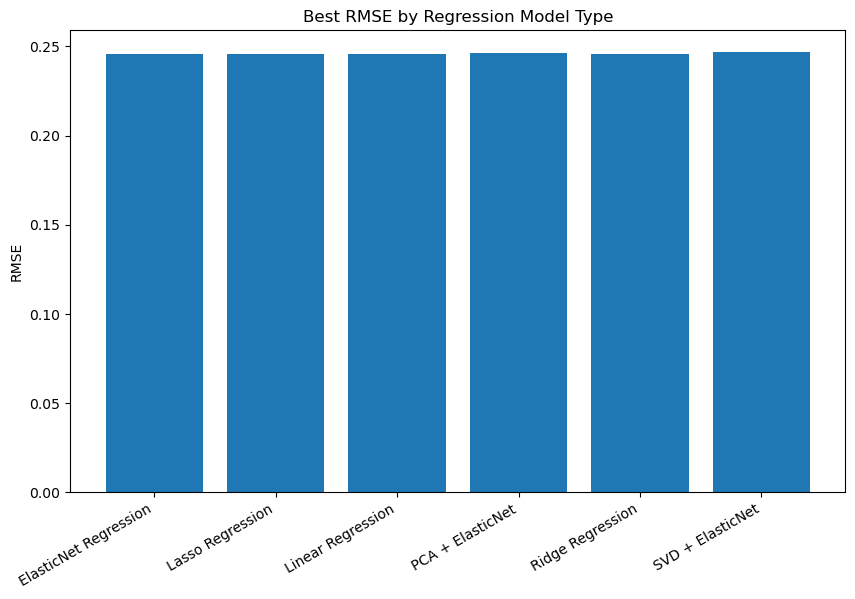

In [39]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

results_df = pd.DataFrame(final_results)

best_each_model = results_df.copy()

best_each_model["Model Type"] = best_each_model["Model"].apply(
    lambda x: (
        "PCA + ElasticNet" if "PCA" in x else
        "SVD + ElasticNet" if "SVD" in x else
        "Linear Regression" if "Linear" in x else
        "Ridge Regression" if "Ridge" in x else
        "Lasso Regression" if "Lasso" in x else
        "ElasticNet Regression" if "ElasticNet" in x else
        "Other"
    )
)

best_each_model = (
    best_each_model
    .sort_values("RMSE")
    .groupby("Model Type", as_index=False)
    .first()
)

plt.figure(figsize=(10, 6))
plt.bar(best_each_model["Model Type"], best_each_model["RMSE"])
plt.ylabel("RMSE")
plt.title("Best RMSE by Regression Model Type")
plt.xticks(rotation=30, ha="right")
plt.show()

The overall model comparison graph summarizes the best-performing configuration from each regression workflow tested in this project. ElasticNet Regression achieved the lowest RMSE and highest overall predictive performance, indicating that combining L1 and L2 regularization provided the best balance between coefficient shrinkage and feature selection. While PCA and SVD dimensionality reduction methods reduced feature dimensionality successfully, the original engineered feature space retained slightly stronger predictive capability. These results suggest that the manually engineered salary, skill, occupation, and economic features already captured highly informative structure within the dataset.

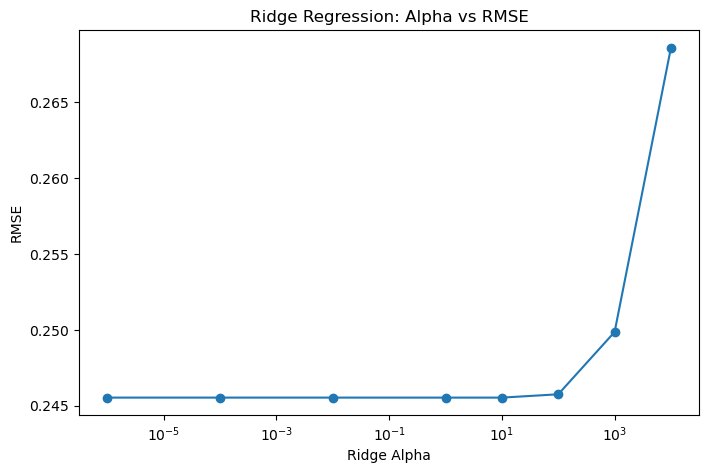

In [40]:
plt.figure(figsize=(8, 5))
plt.plot(ridge_alphas, ridge_rmse, marker="o")
plt.xscale("log")
plt.xlabel("Ridge Alpha")
plt.ylabel("RMSE")
plt.title("Ridge Regression: Alpha vs RMSE")
plt.show()

The Ridge Regression graph illustrates the relationship between regularization strength and predictive performance. Smaller alpha values produced results similar to standard Linear Regression, while larger alpha values gradually reduced model performance due to excessive coefficient shrinkage. This demonstrates the tradeoff between model flexibility and over-regularization.

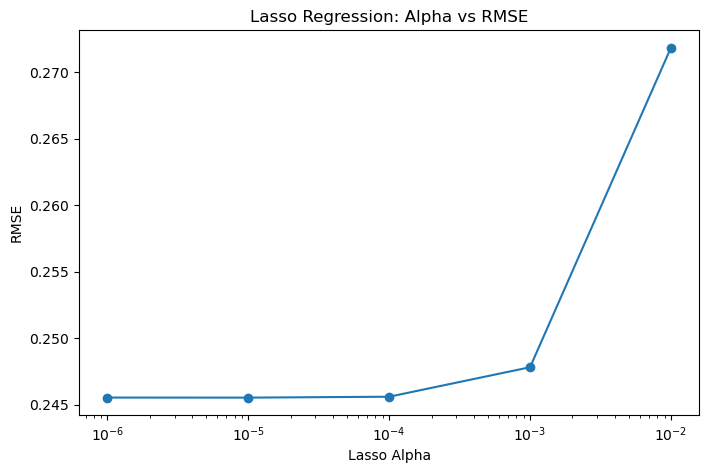

In [41]:
plt.figure(figsize=(8, 5))
plt.plot(lasso_alphas, lasso_rmse, marker="o")
plt.xscale("log")
plt.xlabel("Lasso Alpha")
plt.ylabel("RMSE")
plt.title("Lasso Regression: Alpha vs RMSE")
plt.show()

The Lasso Regression graph shows that stronger L1 regularization led to worse predictive performance. This indicates that many of the engineered features contributed useful predictive information to the fairness index model. Excessive sparsity reduced the model’s ability to capture important relationships within the dataset.

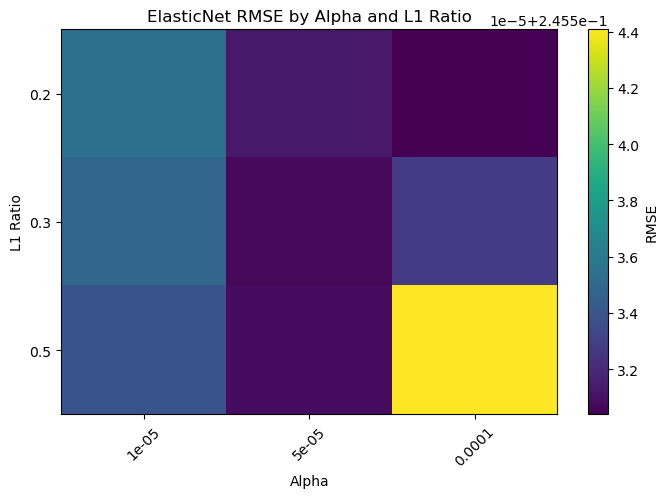

In [42]:
elastic_df = pd.DataFrame(elastic_results)

elastic_pivot = elastic_df.pivot(
    index="l1_ratio",
    columns="alpha",
    values="rmse"
)

plt.figure(figsize=(8, 5))
plt.imshow(elastic_pivot, aspect="auto")
plt.colorbar(label="RMSE")
plt.xticks(
    ticks=np.arange(len(elastic_pivot.columns)),
    labels=elastic_pivot.columns,
    rotation=45
)
plt.yticks(
    ticks=np.arange(len(elastic_pivot.index)),
    labels=elastic_pivot.index
)
plt.xlabel("Alpha")
plt.ylabel("L1 Ratio")
plt.title("ElasticNet RMSE by Alpha and L1 Ratio")
plt.show()

The ElasticNet heatmap visualizes how combinations of alpha and l1_ratio affected RMSE performance. Weak-to-moderate alpha values produced the best results, while configurations with more aggressive sparsity performed slightly worse. This suggests that moderate regularization with limited feature sparsity was most effective for the engineered feature set.

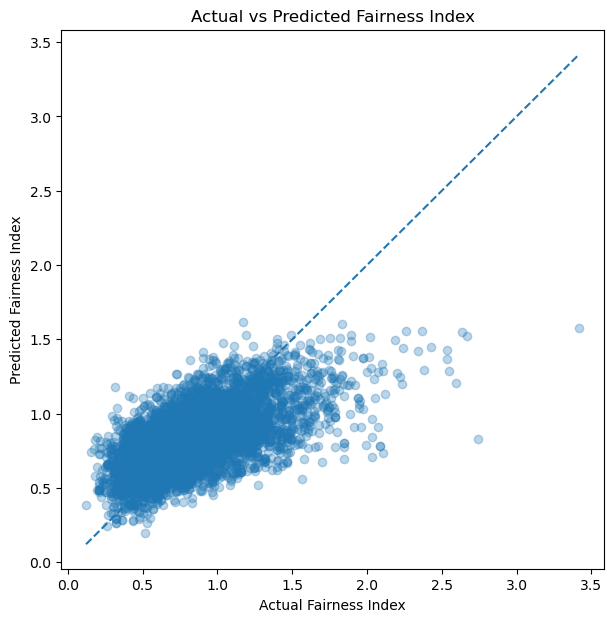

In [43]:
plt.figure(figsize=(7, 7))
plt.scatter(y_test, best_elastic_preds, alpha=0.3)

min_val = min(y_test.min(), best_elastic_preds.min())
max_val = max(y_test.max(), best_elastic_preds.max())
plt.plot([min_val, max_val], [min_val, max_val], linestyle="--")

plt.xlabel("Actual Fairness Index")
plt.ylabel("Predicted Fairness Index")
plt.title("Actual vs Predicted Fairness Index")
plt.show()

The Actual vs Predicted graph compares the model’s predicted fairness index values to the true values in the test set. Ideally, predictions would align closely along a diagonal line, indicating perfect prediction accuracy. The graph demonstrates that the ElasticNet model successfully captured general fairness trends, although some prediction variance remained due to the complexity and noise of real-world salary data.

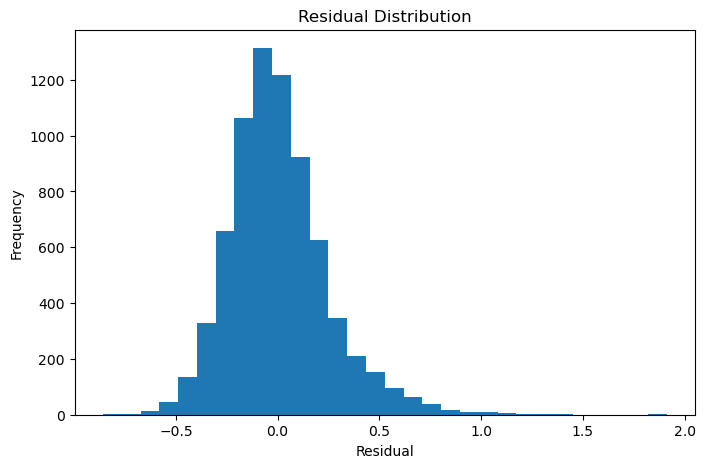

In [44]:
residuals = y_test - best_elastic_preds

plt.figure(figsize=(8, 5))
plt.hist(residuals, bins=30)
plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Residual Distribution")
plt.show()

The residual distribution graph visualizes the prediction errors produced by the ElasticNet model. Most residuals are centered around zero, indicating that the model does not exhibit strong systematic overprediction or underprediction bias. The approximately symmetric distribution suggests relatively stable regression performance across the dataset.

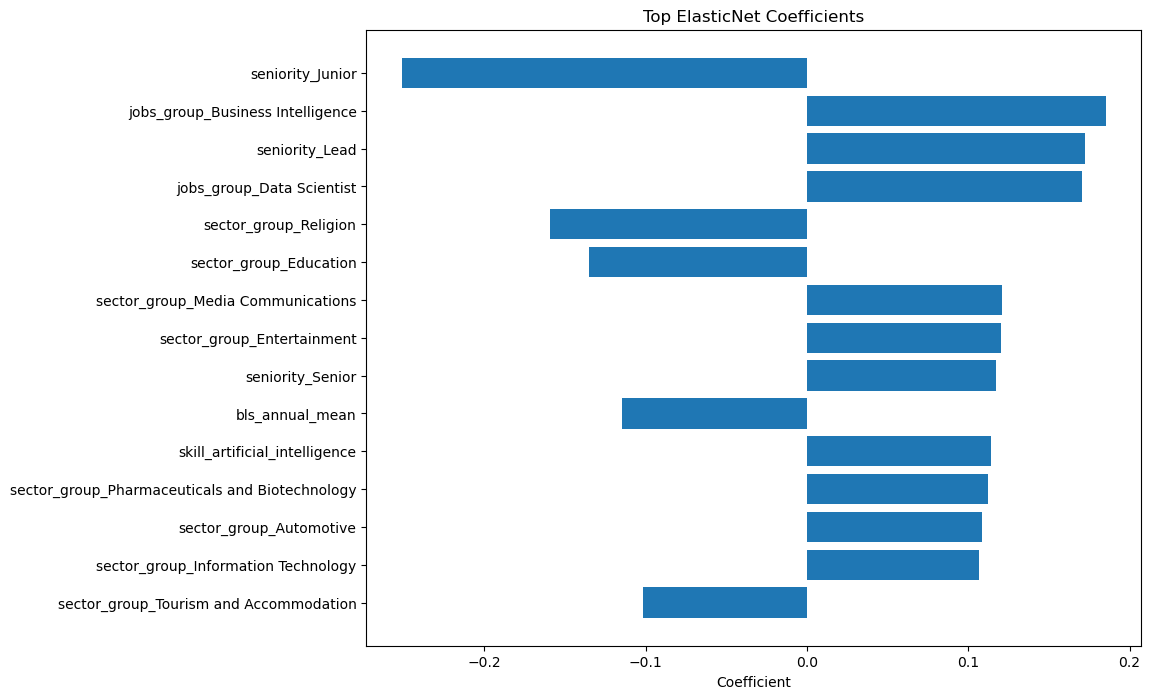

In [45]:
coef_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": best_elastic_model.coef_
})

coef_df["Abs Coefficient"] = coef_df["Coefficient"].abs()

top_coef = coef_df.sort_values(
    by="Abs Coefficient",
    ascending=False
).head(15)

plt.figure(figsize=(10, 8))
plt.barh(top_coef["Feature"], top_coef["Coefficient"])
plt.xlabel("Coefficient")
plt.title("Top ElasticNet Coefficients")
plt.gca().invert_yaxis()
plt.show()

The coefficient importance graph highlights the features that contributed most strongly to the ElasticNet model’s predictions. Positive coefficients indicate features associated with higher predicted fairness index values, while negative coefficients indicate features associated with lower predicted fairness. The graph provides interpretability by showing how skills, sectors, occupations, and economic indicators influenced the model’s predictions.

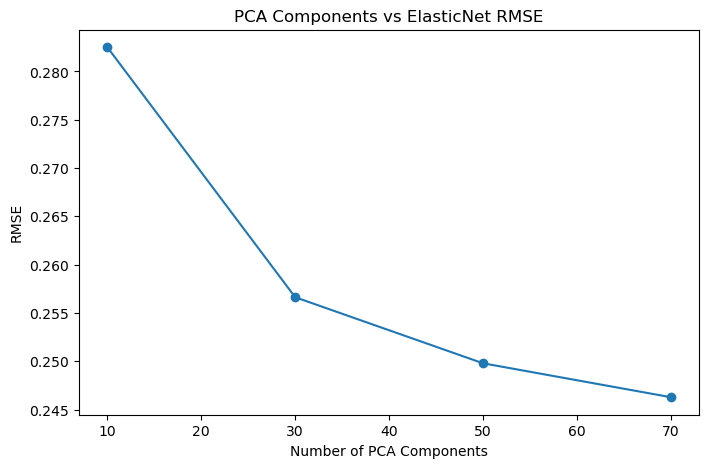

In [46]:
pca_df = pd.DataFrame(pca_results)

plt.figure(figsize=(8, 5))

plt.plot(
    pca_df["components"],
    pca_df["rmse"],
    marker="o"
)

plt.xlabel("Number of PCA Components")
plt.ylabel("RMSE")
plt.title("PCA Components vs ElasticNet RMSE")

plt.show()

The PCA graph demonstrates that predictive performance improved as additional principal components were retained. Lower component counts compressed the feature space too aggressively, resulting in information loss and reduced predictive accuracy. Retaining more components preserved additional variance and improved model performance, although the original non-PCA ElasticNet model still performed slightly better overall.

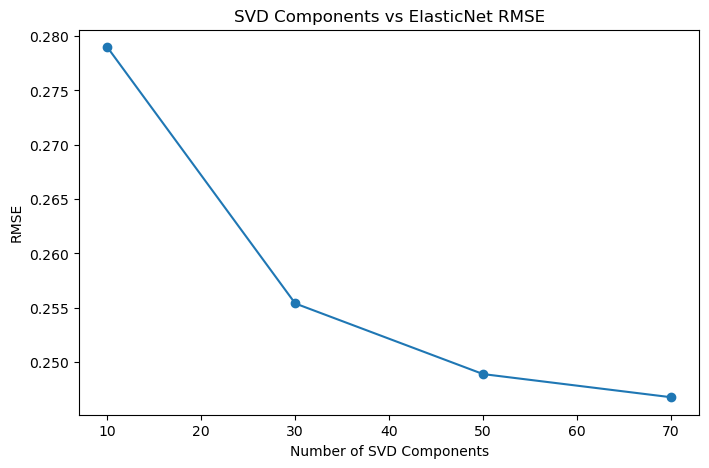

In [47]:
svd_df = pd.DataFrame(svd_results)

plt.figure(figsize=(8,5))

plt.plot(
    svd_df["components"],
    svd_df["rmse"],
    marker="o"
)

plt.xlabel("Number of SVD Components")
plt.ylabel("RMSE")
plt.title("SVD Components vs ElasticNet RMSE")

plt.show()

The SVD graph shows that retaining additional latent components improved model accuracy by preserving more information from the original feature space. However, even the best SVD configuration slightly underperformed compared to the original ElasticNet model, suggesting that the original engineered features already captured highly informative predictive structure.

## Conclusion

Overall, this project explored multiple regression and dimensionality reduction techniques for predicting the fairness index using engineered salary, skill, occupation, sector, and economic features. Linear Regression provided a strong baseline, while Ridge and Lasso Regression demonstrated the effects of coefficient regularization and feature sparsity. ElasticNet achieved the best overall predictive performance by balancing L1 and L2 regularization simultaneously. Additional PCA and SVD experiments showed that dimensionality reduction could preserve much of the predictive structure within the dataset, although the original engineered features remained slightly more effective. The final workflow demonstrated the importance of feature engineering, regularization, cross-validation, and dimensionality reduction in building interpretable and robust machine learning regression models.